In [ ]:
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")

# 1. DATA LOADING
def load_and_clean(filepath):
    df = pd.read_csv(filepath)
    # Standardize column names
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("/", "_")
    
    # Cleaning and Date Conversion
    df = df.drop_duplicates().copy()
    for col in ["date_of_admission", "discharge_date"]:
        df[col] = pd.to_datetime(df[col], errors="coerce")
    
    # Feature Engineering
    df["length_of_stay"] = (df["discharge_date"] - df["date_of_admission"]).dt.days
    df.loc[df["length_of_stay"] < 0, "length_of_stay"] = np.nan
    
    # NEW: Clinical Synergy & Intensity Interaction
    df['clinical_synergy'] = df['medical_condition'].astype(str) + "_" + df['medication'].astype(str)
    df['test_intensity'] = df['test_results'].map({'Normal': 1, 'Abnormal': 2, 'Inconclusive': 1.5})
    
    # Target Creation
    df["billing_category"] = pd.qcut(df["billing_amount"], q=3, labels=["Low", "Medium", "High"])
    return df

# 2. PREPROCESSING PIPELINE
def get_preprocessor(X):
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
    
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]), categorical_features)
        ]
    )
    return preprocessor

# 3. EXECUTION
df = load_and_clean("healthcare_dataset_with_system.csv")

# Define Features and Target
X = df.drop(columns=["billing_amount", "billing_category", "name", "date_of_admission", "discharge_date", "doctor", "hospital"])
y = df["billing_category"]

# Robust Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. ROBUST VALIDATION (Stratified K-Fold)
preprocessor = get_preprocessor(X_train)
model = RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1)

clf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(clf_pipeline, X_train, y_train, cv=skf, scoring=['f1_macro'], n_jobs=-1)

print(f"Mean CV Macro F1: {cv_results['test_f1_macro'].mean():.4f}")

Mean CV Macro F1: 0.4104


In [ ]:
# 1. Define the original features from your v4 notebook
baseline_features = [
    'age', 'gender', 'blood_type', 'medical_condition', 'admission_type', 
    'medication', 'test_results', 'hospital_system', 'length_of_stay', 
    'is_emergency', 'is_urgent', 'weekend_admission', 'long_stay_flag', 'senior_flag'
]

# 2. Define the new features you just engineered
enhanced_features = baseline_features + ['clinical_synergy', 'test_intensity']

# 3. Define the models for the re-run
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression

models_to_compare = {
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=4000, multi_class="multinomial")
}

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def get_preprocessor(X):
    # Identify numeric and categorical columns within the current subset
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
    
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]), categorical_features)
        ]
    )
    return preprocessor

In [ ]:
from sklearn.model_selection import cross_validate, StratifiedKFold

# 1. Initialize the CV strategy
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_data = []

# 2. Loop through feature sets (Baseline vs. Enhanced)
for feature_label, feature_list in [("Baseline", baseline_features), ("Enhanced", enhanced_features)]:
    
    # Ensure all features exist in your dataframe
    available_features = [f for f in feature_list if f in df.columns]
    X_subset = df[available_features]
    y = df['billing_category'] # Your primary target
    
    # Call the preprocessor function defined in Cell 2
    preprocessor = get_preprocessor(X_subset)
    
    # 3. Loop through models (Random Forest, Extra Trees, etc.)
    for model_name, model in models_to_compare.items():
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])
        
        # Performance check using Macro F1 to handle the 3-class target
        cv_results = cross_validate(
            pipeline, X_subset, y, 
            cv=skf, 
            scoring=['f1_macro', 'accuracy'], 
            n_jobs=-1
        )
        
        results_data.append({
            "Feature Set": feature_label,
            "Model": model_name,
            "Mean Macro F1": cv_results['test_f1_macro'].mean(),
            "Std Dev": cv_results['test_f1_macro'].std()
        })

# 4. Display the final results table using standard Pandas
results_df = pd.DataFrame(results_data).sort_values(by="Mean Macro F1", ascending=False)

# Use display() for a nice formatted table in Colab, or just print()
display(results_df)


  Feature Set                Model  Mean Macro F1   Std Dev
1    Baseline          Extra Trees       0.430323  0.001310
3    Enhanced        Random Forest       0.430249  0.002330
4    Enhanced          Extra Trees       0.430066  0.002481
0    Baseline        Random Forest       0.428791  0.003767
2    Baseline  Logistic Regression       0.335450  0.003400
5    Enhanced  Logistic Regression       0.330966  0.004164

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define the parameter grid
# We focus on depth and tree size to balance performance and stability
param_dist = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [10, 20, 30, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

# 2. Setup the Search
# This uses the 'clf_pipeline' and 'skf' strategy from your earlier cells
random_search = RandomizedSearchCV(
    clf_pipeline, 
    param_distributions=param_dist, 
    n_iter=10, 
    cv=skf, 
    scoring='f1_macro', 
    n_jobs=-1, 
    random_state=42
)

# 3. Execute the search
print("Optimizing Random Forest parameters...")
random_search.fit(X_train, y_train)

print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Optimized CV Macro F1: {random_search.best_score_:.4f}")

# Extract the best version of the pipeline for plotting
best_pipeline = random_search.best_estimator_

Optimizing Random Forest parameters...
Best Parameters: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 30}
Best Optimized CV Macro F1: 0.4118


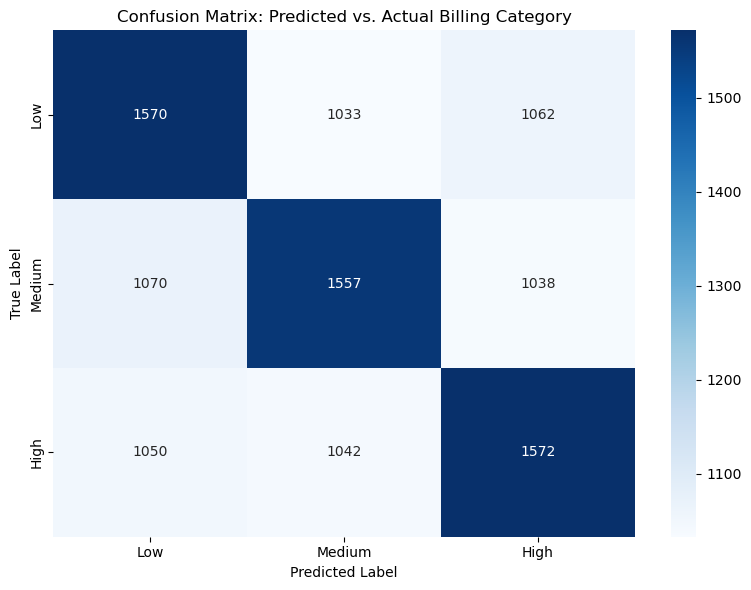

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_styled_confusion_matrix(pipeline, X_test, y_test):
    # 1. Generate predictions
    y_pred = pipeline.predict(X_test)
    
    # 2. Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"])
    
    # 3. Plotting
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=["Low", "Medium", "High"], 
                yticklabels=["Low", "Medium", "High"])
    plt.title('Confusion Matrix: Predicted vs. Actual Billing Category')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()

# Run it on your best pipeline from the previous step
plot_styled_confusion_matrix(best_pipeline, X_test, y_test)

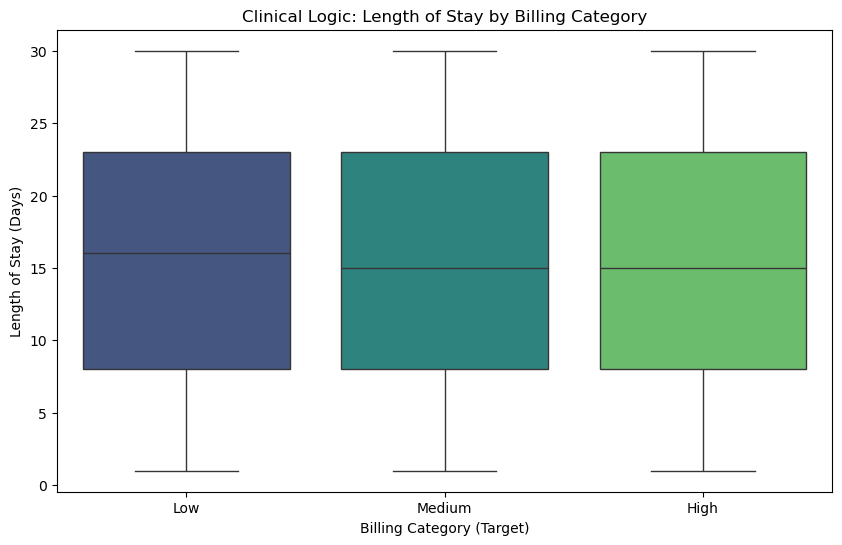

In [ ]:
def plot_clinical_logic(df):
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x='billing_category', y='length_of_stay', 
                order=["Low", "Medium", "High"], palette='viridis')
    plt.title('Clinical Logic: Length of Stay by Billing Category')
    plt.xlabel('Billing Category (Target)')
    plt.ylabel('Length of Stay (Days)')
    plt.show()

# Run on your main dataframe
plot_clinical_logic(df)

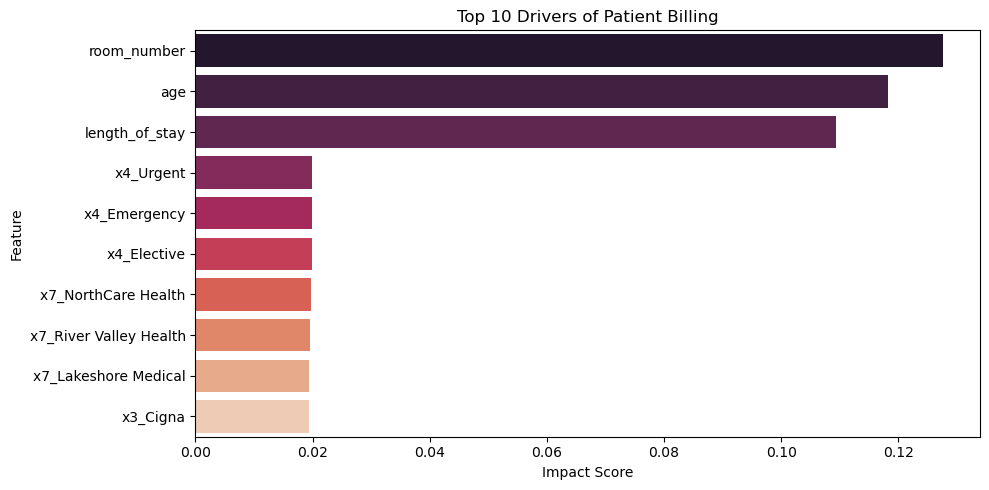

In [ ]:
def plot_final_importance(fitted_pipeline, top_n=10):
    preprocessor = fitted_pipeline.named_steps['preprocessor']
    ohe_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out()
    num_names = preprocessor.transformers_[0][2]
    all_names = np.concatenate([num_names, ohe_names])
    
    importances = fitted_pipeline.named_steps['model'].feature_importances_
    feat_df = pd.DataFrame({'feature': all_names, 'importance': importances})
    feat_df = feat_df.sort_values(by='importance', ascending=False).head(top_n)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(data=feat_df, x='importance', y='feature', palette='rocket')
    plt.title(f'Top {top_n} Drivers of Patient Billing')
    plt.xlabel('Impact Score')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

plot_final_importance(best_pipeline)

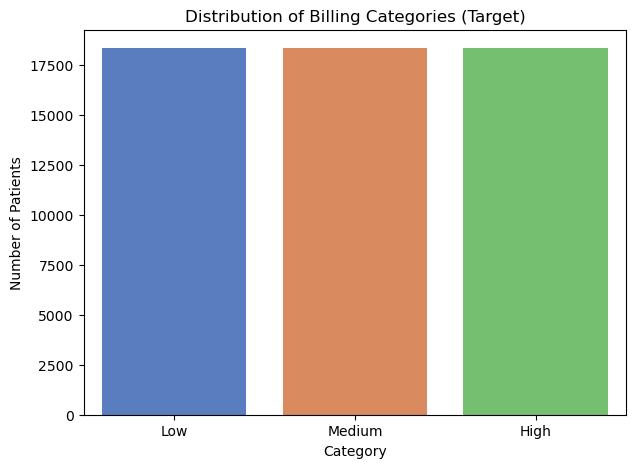

In [ ]:
def plot_target_distribution(df):
    plt.figure(figsize=(7, 5))
    sns.countplot(data=df, x='billing_category', palette='muted', order=["Low", "Medium", "High"])
    plt.title('Distribution of Billing Categories (Target)')
    plt.xlabel('Category')
    plt.ylabel('Number of Patients')
    plt.show()

plot_target_distribution(df)

In [ ]:
!pip install xgboost

[Publication note: original package-installation log omitted; installation command retained above.]


In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# 1. XGBoost requires numeric targets for multiclass (0, 1, 2)
# We encode our "Low", "Medium", "High" categories
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# 2. Define the XGBoost Model
# We start with sensible defaults for a dataset of this size
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,  # Lower learning rate often improves generalization
    max_depth=6,         # XGBoost trees are typically shallower than RF
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

# 3. Create the Pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

# 4. Execute Robust Cross-Validation
print("Evaluating XGBoost with 5-Fold Cross-Validation...")
xgb_cv = cross_validate(
    xgb_pipeline, 
    X_train, 
    y_train_encoded, 
    cv=skf, 
    scoring=['f1_macro', 'accuracy'], 
    n_jobs=-1
)

print(f"XGBoost Mean Macro F1: {xgb_cv['test_f1_macro'].mean():.4f}")
print(f"XGBoost Mean Accuracy: {xgb_cv['test_accuracy'].mean():.4f}")

Evaluating XGBoost with 5-Fold Cross-Validation...
XGBoost Mean Macro F1: 0.3544
XGBoost Mean Accuracy: 0.3544
